# Дополнительная лабораторная. Исследование персептрона

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "91_mlp_investigation"
OUT.mkdir(exist_ok=True, parents=True)

## Данные Linnerud и исходная сеть

20 объектов, по три входа и выхода. Данные масштабирую через StandardScaler. По заданию тестовая выборка не нужна. MLPRegressor: lbfgs, tanh, два слоя по 15 нейронов, random_state = 1, max_iter = 5000. Оптимизатор достиг лимита итераций, train MSE = 2.158.

Train MSE: 2.158165312489561 итераций: 5000


site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


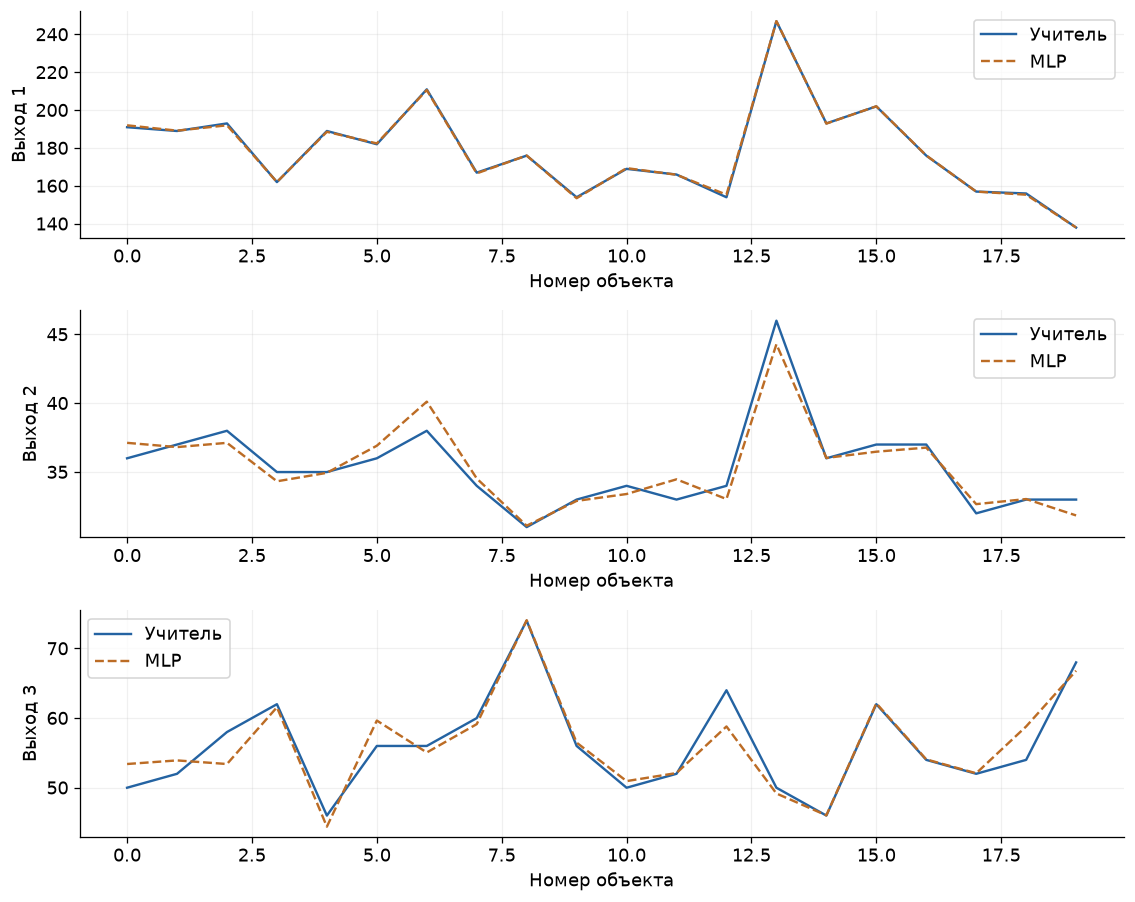

Эта лабораторная исследует обученную функцию на обучающих данных. Полученная train MSE не является оценкой обобщения. Последний слой регрессора использует identity-активацию, скрытые слои — tanh.

In [2]:
from sklearn.datasets import load_linnerud
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from copy import deepcopy

X, y = load_linnerud(return_X_y=True)
scaler = StandardScaler().fit(X)
scaled = scaler.transform(X)
regr = MLPRegressor(
    hidden_layer_sizes=(15, 15),
    activation="tanh",
    solver="lbfgs",
    random_state=1,
    max_iter=5000,
    max_fun=30000,
).fit(scaled, y)
pred = regr.predict(scaled)
mse = mean_squared_error(y, pred)
print("Train MSE:", mse, "итераций:", regr.n_iter_)
assert mse < 50
fig, ax = plt.subplots(3, 1, figsize=(10, 8))
for j, a in enumerate(ax):
    a.plot(y[:, j], label="Учитель")
    a.plot(pred[:, j], "--", label="MLP")
    a.set(xlabel="Номер объекта", ylabel=f"Выход {j+1}")
    a.legend()
showfig("training_outputs", OUT)
note(
    "Эта лабораторная исследует обученную функцию на обучающих данных. Полученная train MSE не является оценкой обобщения. Последний слой регрессора использует identity-активацию, скрытые слои — tanh."
)

## Эксперимент 1. Изменение одного входа

Меняю первый вход от −50 до 50 в 1000 точках, остальные фиксирую. Вычисляю выходы сразу для всего массива.

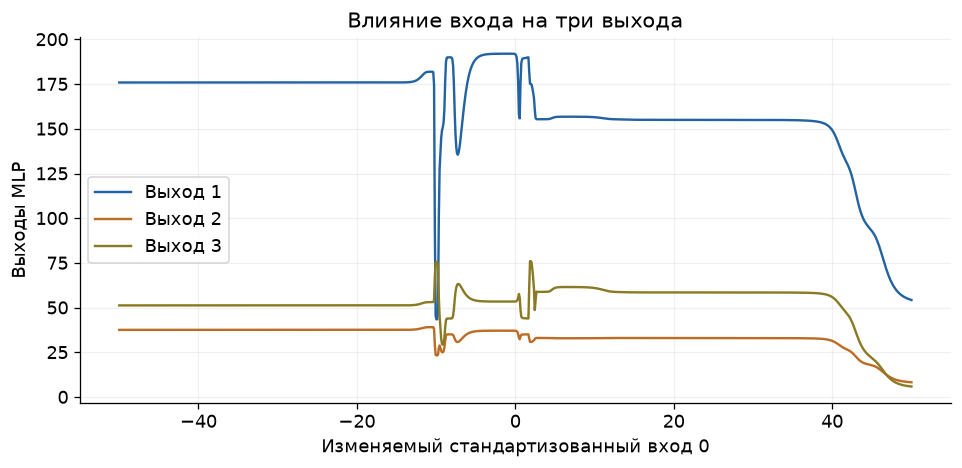

Размер входа: 3 формы: (1000, 3) (1000,)


При сильном отклонении стандартизованного входа tanh может насыщаться, поэтому зависимость выхода становится почти плоской. Интервал [−50,50] далеко выходит за обычный диапазон обучающих стандартизованных значений; это исследование чувствительности, качество экстраполяции не установлено.

In [3]:
def input_change_experiment(regr, input_vec, input_id, value_range, num):
    base = np.asarray(input_vec, dtype=float).reshape(1, -1)
    if base.shape[1] != regr.n_features_in_:
        raise ValueError("Неверная размерность входа")
    x_line = np.linspace(value_range[0], value_range[1], num)
    batch = np.repeat(base, num, axis=0)
    batch[:, input_id] = x_line
    return regr.predict(batch), x_line


outputs, xline = input_change_experiment(
    regr, np.array([[0, 0, 0]]), 0, (-50, 50), 1000
)
plt.plot(xline, outputs)
plt.xlabel("Изменяемый стандартизованный вход 0")
plt.ylabel("Выходы MLP")
plt.title("Влияние входа на три выхода")
plt.legend(["Выход 1", "Выход 2", "Выход 3"])
showfig("input_sensitivity", OUT)
print("Размер входа:", regr.n_features_in_, "формы:", outputs.shape, xline.shape)
assert outputs.shape == (1000, 3)
note(
    "При сильном отклонении стандартизованного входа tanh может насыщаться, поэтому зависимость выхода становится почти плоской. Интервал [−50,50] далеко выходит за обычный диапазон обучающих стандартизованных значений; это исследование чувствительности, качество экстраполяции не установлено."
)

## Эксперимент 2. Изменение одного веса

Изменяю вес [0, 0, 0] в копии модели, исходные веса сохраняю. Вход — [1, 1, 1].

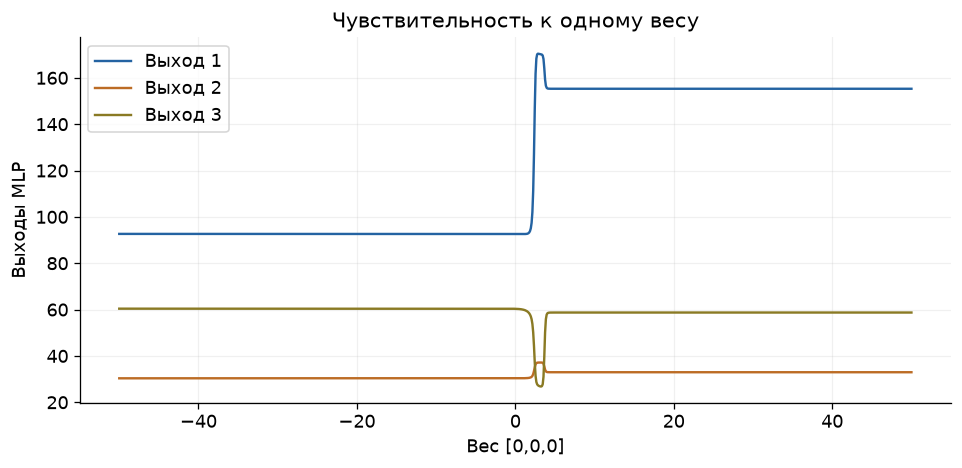

Формы матриц весов: [(3, 15), (15, 15), (15, 3)]
Вход [0,0,0] занулил бы вклад изменяемого входного веса, поэтому выбран [1,1,1].


Сдвиг одного веса меняет активацию одного скрытого нейрона, а через него — несколько выходов. Участки насыщения tanh объясняют малую чувствительность при больших |w|. Поведение остальных весов фиксировано, исходная модель не изменена.

In [4]:
def weight_change_experiment(regr, input_vec, weight_id, value_range, num):
    reg = deepcopy(regr)
    base = np.asarray(input_vec, dtype=float).reshape(1, -1)
    wline = np.linspace(value_range[0], value_range[1], num)
    out = np.empty((num, regr.n_outputs_))
    layer, feature, neuron = weight_id
    for i, weight in enumerate(wline):
        reg.coefs_[layer][feature, neuron] = weight
        out[i] = reg.predict(base)[0]
    return out, wline


before = [a.copy() for a in regr.coefs_]
outputs, wline = weight_change_experiment(
    regr, np.array([[1, 1, 1]]), [0, 0, 0], (-50, 50), 1000
)
assert all(np.array_equal(a, b) for a, b in zip(before, regr.coefs_))
plt.plot(wline, outputs)
plt.xlabel("Вес [0,0,0]")
plt.ylabel("Выходы MLP")
plt.title("Чувствительность к одному весу")
plt.legend(["Выход 1", "Выход 2", "Выход 3"])
showfig("weight_sensitivity", OUT)
print("Формы матриц весов:", [a.shape for a in regr.coefs_])
print(
    "Вход [0,0,0] занулил бы вклад изменяемого входного веса, поэтому выбран [1,1,1]."
)
note(
    "Сдвиг одного веса меняет активацию одного скрытого нейрона, а через него — несколько выходов. Участки насыщения tanh объясняют малую чувствительность при больших |w|. Поведение остальных весов фиксировано, исходная модель не изменена."
)